# Activité Pratique N°1 — Mise en oeuvre du Framework PyTorch

**Étapes 0 à 18** : les bases de PyTorch (tensors, autograd, `nn.Module`, loss, optimizer,
boucle d'apprentissage, `DataLoader`), puis une régression et une classification complètes.

Les exercices 1 à 4 sont dans des notebooks séparés (`Exercice 1 - Salaires.ipynb`, etc.).

## 0. Préparation

In [1]:
# Préparation
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu126
CUDA disponible: True


## 1. Workflow général

Le cycle de base est :

**Données → Tensors → Modèle → Prédictions → Loss → Backward → Optimizer → Mise à jour**

In [2]:
# Pseudo-code de la logique générale
# y_pred = model(X)
# loss = criterion(y_pred, y)
# optimizer.zero_grad()
# loss.backward()
# optimizer.step()

## 2. Les Tensors

In [3]:
# Tensors
scalar = torch.tensor(3.0)
vector = torch.tensor([1.0,2.0,3.0])
matrix = torch.tensor([[1.0,2.0],[3.0,4.0]])

print("scalar:",scalar,"shape = ",scalar.shape)
print("vector:",vector,"shape = ",vector.shape)
print("matrix:",matrix, "shape = ", matrix.shape)
print("dtype: ", matrix.dtype)
print("ndim:", matrix.ndim)

scalar: tensor(3.) shape =  torch.Size([])
vector: tensor([1., 2., 3.]) shape =  torch.Size([3])
matrix: tensor([[1., 2.],
        [3., 4.]]) shape =  torch.Size([2, 2])
dtype:  torch.float32
ndim: 2


### Manipulation de Tensors

In [4]:
# Opération sur les tenseurs
x = torch.arange(12)
print("x=",x)

x2=x.reshape(3,4)
print("reshape(3,4):",x2)

print("colonne 1: ", x2[:,1])
print("ligne 0: ", x2[0,:])

A = torch.tensor([[1., 2.], [3., 4.]])
B = torch.tensor([[2., 0.], [1.,2.]])
print("A @ B = ", A@B)

print("mean(A)=", A.mean())
print("sum(A)=", A.sum())

x= tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
reshape(3,4): tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])
colonne 1:  tensor([1, 5, 9])
ligne 0:  tensor([0, 1, 2, 3])
A @ B =  tensor([[ 4.,  4.],
        [10.,  8.]])
mean(A)= tensor(2.5000)
sum(A)= tensor(10.)


## 3. CPU, GPU et `device`

In [5]:
#CPU, GPU et Devide
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device utilisé:", device)

x = torch.tensor([1.0, 2.0, 3.0]).to(device)
print("x.device =", x.device)

Device utilisé: cuda
x.device = cuda:0


## 4. Autograd

In [6]:
# Autograd
x = torch.tensor(2.0)
w = torch.tensor(3.0, requires_grad = True)
b = torch.tensor(1.0, requires_grad = True)
y = w * x + b
loss = (y - 10) ** 2
# 10 est sûrement le label réel de 2.0


In [7]:
loss.backward()
print("y = ", y.item())
print("loss = ", loss.item())
print("dLoss/dw = ", w.grad.item())
print("dLoss/db = ", b.grad.item())

y =  7.0
loss =  9.0
dLoss/dw =  -12.0
dLoss/db =  -6.0


In [8]:
# Une autre façon de faire : torch.autograd.grad
# backward() a libéré le graphe de calcul, on recalcule donc y et loss avant
y = w * x + b
loss = (y - 10) ** 2
dw, db = torch.autograd.grad(loss, (w, b))
print("y = ", y.item())
print("loss = ", loss.item())
print("dLoss/dw = ", dw.item())
print("dLoss/db = ", db.item())

y =  7.0
loss =  9.0
dLoss/dw =  -12.0
dLoss/db =  -6.0


### Vérification analytique

In [9]:
# Vérification analytique
'''
y = wx + b

L = (y - 10)²
L = (wx + b - 10)²
dL/dw = 2 d(wx + b - 10)/dw (wx + b - 10)
dL/dw = 2(y - 10)x
dL/db = 2 d(wx + b - 10)/db (wx + b - 10)
dL/db = 2(y - 10)
'''
y_val = (3.0 * 2.0 + 1.0)
dL_dw = 2 * (y_val - 10) * 2.0
dL_db = 2 * (y_val - 10)
print(dL_dw, dL_db)

-12.0 -6.0


## 5. Un neurone avec `nn.Linear`

In [10]:
# Un neuron avec nn.Linear
# z = (sigma wi xi )+ b
import torch
import torch.nn as nn
from torchviz import make_dot
model = nn.Linear(3, 1)
x = torch.tensor([[1.0, 2.0, 3.0]])
y = model(x)
print("Sortie: ", y)
print("Poids: ", model.weight)
print("Biais: ", model.bias)
dot = make_dot(y, params=dict(model.named_parameters()))
dot.render("graphe_operations", format="png", cleanup=True)

Sortie:  tensor([[-0.2272]], grad_fn=<AddmmBackward0>)
Poids:  Parameter containing:
tensor([[-0.4666,  0.5606, -0.2378]], requires_grad=True)
Biais:  Parameter containing:
tensor([-0.1685], requires_grad=True)


'graphe_operations.png'

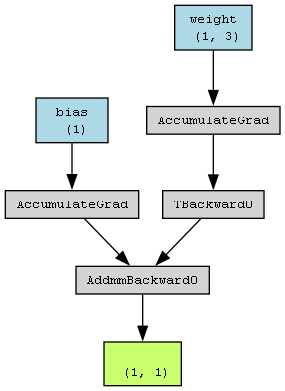

In [11]:
from IPython.display import Image, display
display(Image(filename="graphe_operations.png"))

## 6. Construire un réseau avec `nn.Module`

In [12]:
# Construire un réseau de neurones
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 3)
        )
    def forward(self, x):
        return self.net(x)
model = MLP()
print(model)

MLP(
  (net): Sequential(
    (0): Linear(in_features=4, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=3, bias=True)
  )
)


### Le même réseau avec `nn.Sequential`

Quand les couches s'enchaînent simplement, `nn.Sequential` suffit. Une classe `nn.Module`
devient utile dès que `forward` fait plus qu'enchaîner les couches (plusieurs entrées, branches...).

In [13]:
model = nn.Sequential(
    nn.Linear(4, 16),
    nn.ReLU(),
    nn.Linear(16, 8),
    nn.ReLU(),
    nn.Linear(8, 3)
)
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=3, bias=True)
)


## 7. Fonctions d'activation

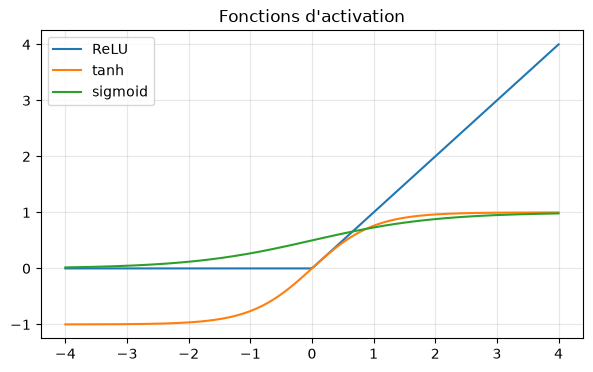

In [14]:
x = torch.linspace(-4, 4, 200)
relu = torch.relu(x)
tanh = torch.tanh(x)
sigmoid = torch.sigmoid(x)

plt.figure(figsize=(7, 4))
plt.plot(x.numpy(), relu.numpy(), label='ReLU')
plt.plot(x.numpy(), tanh.numpy(), label='tanh')
plt.plot(x.numpy(), sigmoid.numpy(), label='sigmoid')
plt.grid(True, alpha=0.3)
plt.legend()
plt.title("Fonctions d'activation")
plt.show()

## 8. Forward propagation

In [15]:
X = torch.randn(5, 4)
# L'appel model(X) déclenche automatiquement model.forward(X)
predicted = model(X)
print("Shape entrée :", X.shape)
print("Shape sortie :", predicted.shape)

Shape entrée : torch.Size([5, 4])
Shape sortie : torch.Size([5, 3])


## 9. Fonctions de coût

In [16]:
# Régression
criterion_reg = nn.MSELoss()
y_pred = torch.tensor([[2.0], [4.0]])
y_true = torch.tensor([[3.0], [5.0]])
print("MSE =", criterion_reg(y_pred, y_true).item())

#classification multi-classe
criterion_cls = nn.CrossEntropyLoss()
pred = torch.tensor([[2.0, 1.0, 0.5], [0.2, 0.1, 2.0]])
y = torch.tensor([0, 2])
print("CrossEntropy =", criterion_cls(pred, y).item())

MSE = 1.0
CrossEntropy = 0.36905235052108765


Le nombre de couches et de paramètres est le même dans les deux écritures.

## 10. Optimizers

L'optimiseur utilise les gradients pour mettre à jour les paramètres.

In [17]:
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    weight_decay: 0
)


## 11. La boucle d'apprentissage

C'est le cœur de PyTorch : prédire, calculer la perte, remettre les gradients à zéro,
rétropropager, mettre à jour.

In [18]:
X = torch.randn(8, 1)
y = 2 * X + 1
simple_model = nn.Linear(1, 1)
optimizer = torch.optim.Adam(simple_model.parameters(), lr=1e-2)
criterion = nn.MSELoss()
epochs = 500

for epoch in range(epochs):
    simple_model.train()
    y_pred = simple_model(X)
    loss = criterion(y_pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print(f"epoch={epoch} loss={loss.item():.4f}")

print("w appris :", simple_model.weight.item(), "(attendu 2)")
print("b appris :", simple_model.bias.item(), "(attendu 1)")

epoch=0 loss=5.0717
epoch=100 loss=2.0199
epoch=200 loss=0.6819
epoch=300 loss=0.1818
epoch=400 loss=0.0373
w appris : 1.9069509506225586 (attendu 2)
b appris : 0.9725672602653503 (attendu 1)


## 12. `train()` vs `eval()`

`model.train()` et `model.eval()` changent le comportement de `Dropout` et `BatchNorm`.

`eval()` ne désactive pas le calcul des gradients : pour l'inférence, on utilise en plus
`torch.inference_mode()` (ou `torch.no_grad()`).

In [19]:
class DropoutDemo(nn.Module):
    def __init__(self):
        super().__init__()
        self.dropout = nn.Dropout(p=0.5)

    def forward(self, x):
        return self.dropout(x)

m = DropoutDemo()
x = torch.ones(10)

m.train()
print("train() :", m(x))

m.eval()
with torch.inference_mode():
    print("eval()  :", m(x))

train() : tensor([2., 0., 2., 2., 0., 0., 2., 2., 0., 0.])
eval()  : tensor([1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])


En mode `train()`, environ la moitié des valeurs est mise à 0 et les autres sont multipliées
par 2 (= 1 / (1 - p)) pour garder la même moyenne. En mode `eval()`, le Dropout ne fait rien.

## 13. Dataset et DataLoader

`TensorDataset` associe les entrées et les cibles ; `DataLoader` les découpe en mini-lots
et les mélange à chaque époque (`shuffle=True`).

In [20]:
X = torch.randn(100, 3)
y = torch.randn(100, 1)

dataset = TensorDataset(X, y)
loader = DataLoader(dataset, batch_size=16, shuffle=True)

for X_batch, y_batch in loader:
    print("Batch X:", X_batch.shape, "Batch y:", y_batch.shape)
    break

print("Nombre de lots :", len(loader))  # 100 / 16 -> 7 lots (le dernier en contient 4)

Batch X: torch.Size([16, 3]) Batch y: torch.Size([16, 1])
Nombre de lots : 7


# Partie pratique 1 — Régression linéaire

Nous générons des données proches de : $y = 3x + 2 + \text{bruit}$

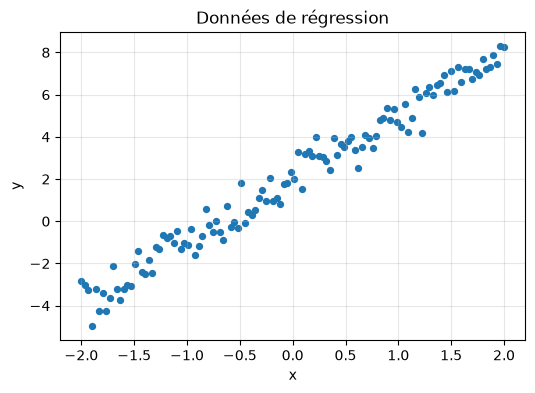

In [21]:
torch.manual_seed(42)

X = torch.linspace(-2, 2, 120).unsqueeze(1)
noise = 0.6 * torch.randn_like(X)
y = 3 * X + 2 + noise

plt.figure(figsize=(6, 4))
plt.scatter(X.numpy(), y.numpy(), s=18)
plt.title("Données de régression")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.show()

## 14. Modèle, loss et optimizer

In [22]:
model_reg = nn.Linear(1, 1)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model_reg.parameters(), lr=0.05)

## 15. Entraînement de la régression

In [23]:
losses = []

for epoch in range(300):
    model_reg.train()

    y_pred = model_reg(X)
    loss = criterion(y_pred, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

print("Dernier loss:", losses[-1])
print("w appris:", model_reg.weight.item())
print("b appris:", model_reg.bias.item())

Dernier loss: 0.3438417613506317
w appris: 2.9894580841064453
b appris: 2.030014991760254


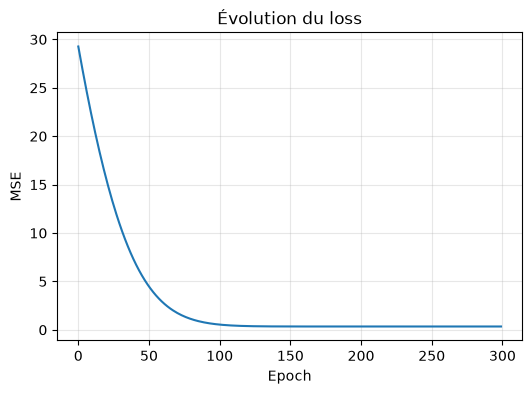

In [24]:
plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Évolution du loss")
plt.grid(True, alpha=0.3)
plt.show()

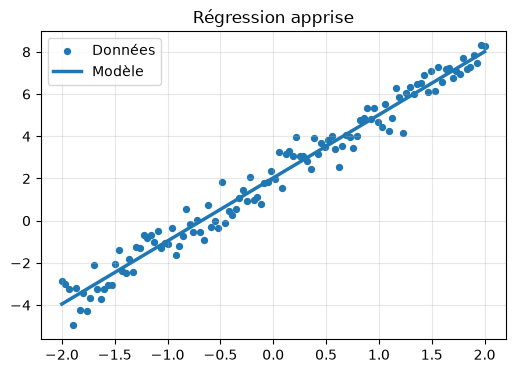

In [25]:
model_reg.eval()
with torch.inference_mode():
    y_hat = model_reg(X)

plt.figure(figsize=(6, 4))
plt.scatter(X.numpy(), y.numpy(), s=18, label="Données")
plt.plot(X.numpy(), y_hat.numpy(), linewidth=2.5, label="Modèle")
plt.legend()
plt.title("Régression apprise")
plt.grid(True, alpha=0.3)
plt.show()

In [26]:
from torcheval.metrics import R2Score

metric = R2Score()
metric.update(y_hat, y)
r2 = metric.compute()
print(f"R2 Score = {r2:.3f}")

C:\Users\user\Desktop\5IAD G1 BENHAYOUN SADAFI Mohamed, emsi, matiere ia multimodale\Activité Pratique N°1 - Mise en oeuvre du Framework PyTorch\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


R2 Score = 0.972


Le modèle retrouve `w ≈ 3` et `b ≈ 2`. La perte ne descend pas à 0 : elle se stabilise vers
la variance du bruit (0,6² ≈ 0,36), qu'aucun modèle ne peut prédire.

# Partie pratique 2 — Classification

Créons deux classes de points en 2D.

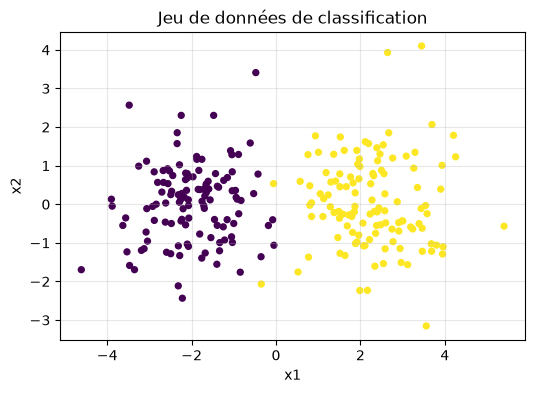

In [27]:
torch.manual_seed(0)

n = 120
class0 = torch.randn(n, 2) + torch.tensor([-2.0, 0.0])
class1 = torch.randn(n, 2) + torch.tensor([ 2.0, 0.0])

X_cls = torch.cat([class0, class1], dim=0)
y_cls = torch.cat([
    torch.zeros(n, dtype=torch.long),
    torch.ones(n, dtype=torch.long)
])

plt.figure(figsize=(6, 4))
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, s=18)
plt.title("Jeu de données de classification")
plt.xlabel("x1")
plt.ylabel("x2")
plt.grid(True, alpha=0.3)
plt.show()

## 16. Modèle de classification

In [28]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 16),
            nn.ReLU(),
            nn.Linear(16, 2)
        )

    def forward(self, x):
        return self.net(x)

model_cls = Classifier()
criterion_cls = nn.CrossEntropyLoss()
optimizer_cls = torch.optim.Adam(model_cls.parameters(), lr=0.01)

## 17. Entraînement de la classification

In [29]:
losses_cls = []

for epoch in range(250):
    model_cls.train()

    logits = model_cls(X_cls)
    loss = criterion_cls(logits, y_cls)

    optimizer_cls.zero_grad()
    loss.backward()
    optimizer_cls.step()

    losses_cls.append(loss.item())

print("Dernier loss:", losses_cls[-1])

Dernier loss: 0.0006943687913008034


In [30]:
model_cls.eval()
with torch.inference_mode():
    logits = model_cls(X_cls)
    pred = logits.argmax(dim=1)
    accuracy = (pred == y_cls).float().mean()

print(f"Accuracy = {accuracy.item()*100:.2f}%")

Accuracy = 100.00%


### Métriques et matrice de confusion

Avec `torcheval`, on passe toujours **la prédiction d'abord, la vraie classe ensuite** :
`metric.update(pred, y_cls)`. Inverser les deux échangerait la précision et le rappel.

Accuracy = 1.0000, precision = 1.0000, recall = 1.0000, f1-score = 1.0000
tensor([[120,   0],
        [  0, 120]])


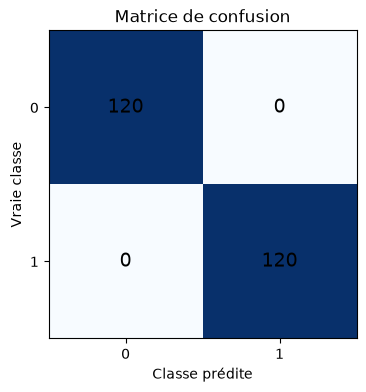

In [31]:
from torcheval.metrics import (BinaryAccuracy, BinaryPrecision, BinaryRecall,
                               BinaryF1Score, BinaryConfusionMatrix)

def calculer(metric):
    metric.update(pred, y_cls)
    return metric.compute()

accuracy_value = calculer(BinaryAccuracy())
precision_value = calculer(BinaryPrecision())
recall_value = calculer(BinaryRecall())
f1_score_value = calculer(BinaryF1Score())
print(f"Accuracy = {accuracy_value:.4f}, precision = {precision_value:.4f}, "
      f"recall = {recall_value:.4f}, f1-score = {f1_score_value:.4f}")

confusion_matrix = calculer(BinaryConfusionMatrix()).long()
print(confusion_matrix)

plt.figure(figsize=(4, 4))
plt.imshow(confusion_matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, confusion_matrix[i, j].item(), ha="center", va="center", fontsize=14)
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.xlabel("Classe prédite")
plt.ylabel("Vraie classe")
plt.title("Matrice de confusion")
plt.show()

### Visualisation de la frontière de décision

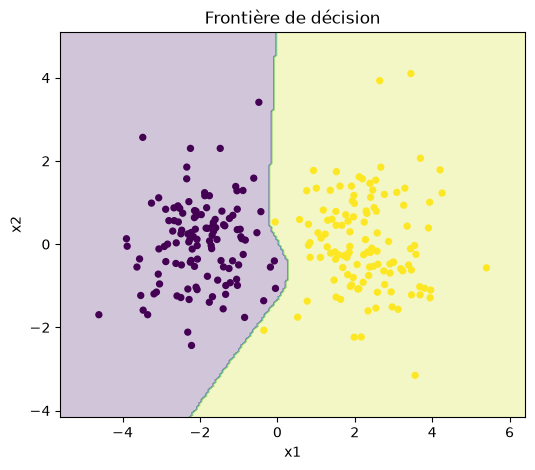

In [32]:
x1_min, x1_max = X_cls[:, 0].min() - 1, X_cls[:, 0].max() + 1
x2_min, x2_max = X_cls[:, 1].min() - 1, X_cls[:, 1].max() + 1

xx1, xx2 = torch.meshgrid(
    torch.linspace(x1_min, x1_max, 200),
    torch.linspace(x2_min, x2_max, 200),
    indexing='ij'
)

grid = torch.stack([xx1.reshape(-1), xx2.reshape(-1)], dim=1)

model_cls.eval()
with torch.inference_mode():
    zz = model_cls(grid).argmax(dim=1).reshape(xx1.shape)

plt.figure(figsize=(6, 5))
plt.contourf(xx1.numpy(), xx2.numpy(), zz.numpy(), alpha=0.25)
plt.scatter(X_cls[:, 0], X_cls[:, 1], c=y_cls, s=18)
plt.title("Frontière de décision")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

## 18. Sauvegarder et recharger un modèle

On sauvegarde le `state_dict` (les poids), puis on le recharge dans un nouveau modèle
de même architecture.

In [33]:
path = "classifier_state_dict.pt"
torch.save(model_cls.state_dict(), path)
print("Modèle sauvegardé dans", path)

new_model = Classifier()
new_model.load_state_dict(torch.load(path, weights_only=True))
new_model.eval()

with torch.inference_mode():
    pred_new = new_model(X_cls).argmax(dim=1)

print("Prédictions identiques:", torch.equal(pred, pred_new))

Modèle sauvegardé dans classifier_state_dict.pt
Prédictions identiques: True


# Synthèse

Les briques essentielles de PyTorch :

1. `Tensor`
2. `nn.Module`
3. `forward()`
4. fonction de coût
5. `optimizer.zero_grad()`
6. `loss.backward()`
7. `optimizer.step()`
8. `train()` / `eval()`
9. `Dataset` / `DataLoader`
10. sauvegarde avec `state_dict()`

Cette mécanique reste la même pour des modèles plus avancés : CNN, Transformers, modèles génératifs.